# Importação das bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# **Geração dos dados e definição das classes**
Vamos gerar 20 mil coordenadas aleatórias dentro do quadrado. Depois, verificaremos quais semicírculos contêm cada ponto.

In [2]:
# Reprodutibilidade dos resultados
np.random.seed(42)

# Quantidade de pontos
N = 20000

# Geração de pontos aleatórios entre -1 e 1
X = np.random.uniform(-1, 1, (N, 2))

# Centros dos quatro semicírculos
centros = np.array([
    [1, 0],
    [-1, 0],
    [0, 1],
    [0, -1]
])

# Verifica se cada ponto pertence a cada semicírculo
distancias = np.linalg.norm(
    X[:, None, :] - centros[None, :, :],
    axis=2
)

dentro = distancias <= 1

# Inicialmente, todos os pontos pertencem à classe 4
y = np.full(N, 4)

# Identificação das quatro regiões de interseção
pares = [
    (0, 2),  # Superior direita
    (1, 2),  # Superior esquerda
    (1, 3),  # Inferior esquerda
    (0, 3)   # Inferior direita
]

for classe, (a, b) in enumerate(pares):
    mascara = dentro[:, a] & dentro[:, b]
    y[mascara] = classe

print("Dados gerados:", X.shape)
print("Classes:", np.unique(y))

Dados gerados: (20000, 2)
Classes: [0 1 2 3 4]


# Visualização dos padrões
É interessante visualizar os dados antes de treinar a rede para verificar se as cinco classes foram construídas corretamente.

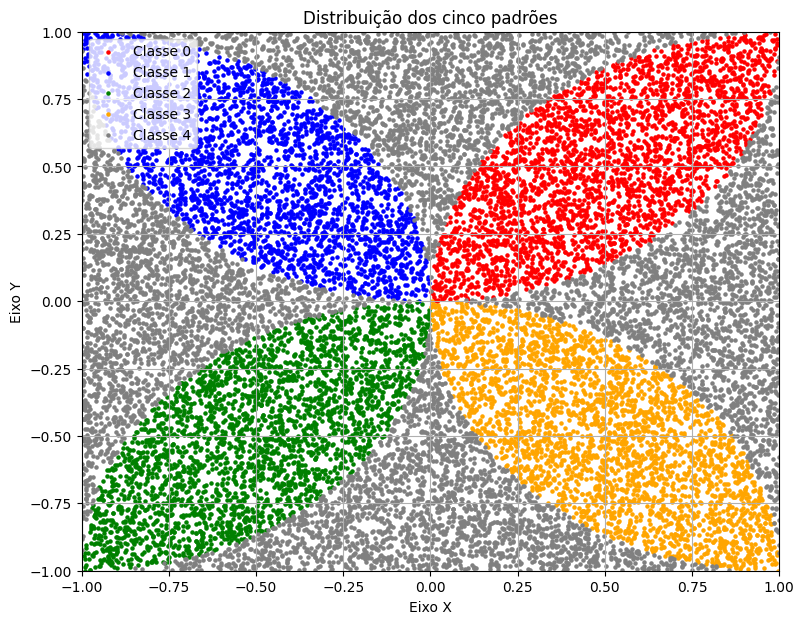

In [3]:
plt.figure(figsize=(9, 7))

cores = ['red', 'blue', 'green', 'orange', 'gray']

for classe in range(5):
    mascara = y == classe

    plt.scatter(
        X[mascara, 0],
        X[mascara, 1],
        c=cores[classe],
        label=f'Classe {classe}',
        s=5
    )

plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.xlabel('Eixo X')
plt.ylabel('Eixo Y')
plt.title('Distribuição dos cinco padrões')
plt.legend()
plt.grid()
plt.show()

# Separação entre treinamento e teste
Vamos utilizar 70% dos dados para ensinar a rede neural e reservar os outros 30% para avaliar sua capacidade de classificação.

In [4]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Dados de treinamento:", X_treino.shape)
print("Dados de teste:", X_teste.shape)

Dados de treinamento: (14000, 2)
Dados de teste: (6000, 2)


# Definição da arquitetura Deep MLP

In [5]:
modelo = make_pipeline(
    StandardScaler(),

    MLPClassifier(
        hidden_layer_sizes=(128, 128, 64, 32),
        activation='relu',
        solver='adam',
        alpha=0.0001,
        batch_size=128,
        learning_rate_init=0.001,
        max_iter=300,
        early_stopping=True,
        n_iter_no_change=20,
        random_state=42
    )
)

# Treinamento da rede neural

In [6]:
modelo.fit(X_treino, y_treino)

print("Treinamento concluído!")
print("Épocas executadas:", modelo[-1].n_iter_)

Treinamento concluído!
Épocas executadas: 57


# Realização das previsões

In [7]:
y_pred = modelo.predict(X_teste)

print("Previsões realizadas com sucesso!")

Previsões realizadas com sucesso!


# Matriz de confusão
A matriz de confusão permite verificar quantas amostras foram classificadas corretamente e quantas foram confundidas com outras classes.

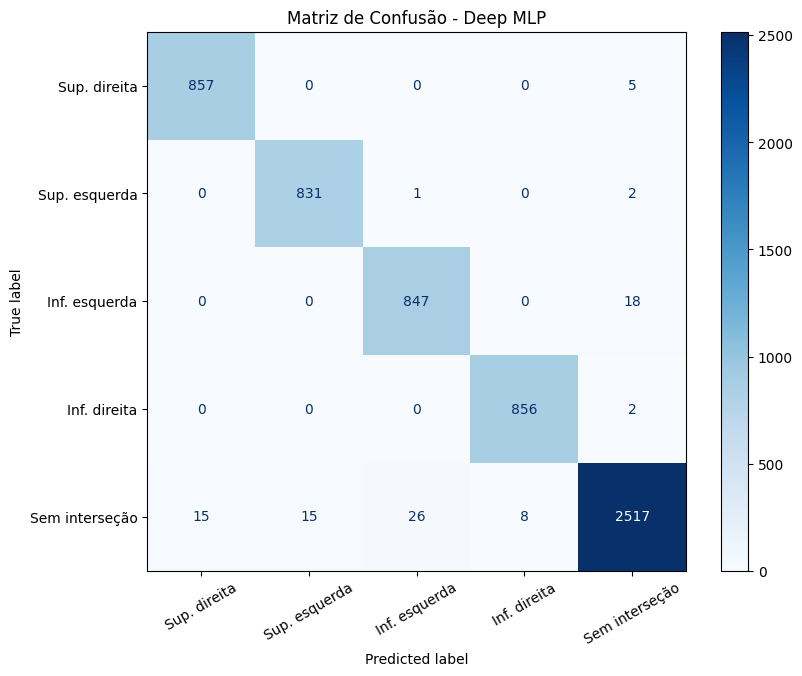

[[ 857    0    0    0    5]
 [   0  831    1    0    2]
 [   0    0  847    0   18]
 [   0    0    0  856    2]
 [  15   15   26    8 2517]]


In [8]:
matriz = confusion_matrix(
    y_teste,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=[
        'Sup. direita',
        'Sup. esquerda',
        'Inf. esquerda',
        'Inf. direita',
        'Sem interseção'
    ]
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Matriz de Confusão - Deep MLP')
plt.xticks(rotation=30)
plt.show()

print(matriz)

# Cálculo das métricas de desempenho

In [9]:
# Acurácia geral
acuracia = accuracy_score(y_teste, y_pred)

print("Acurácia:", round(acuracia, 4))

# Precisão, recall e F1-score por classe
print(classification_report(
    y_teste,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=[
        'Superior direita',
        'Superior esquerda',
        'Inferior esquerda',
        'Inferior direita',
        'Sem interseção'
    ],
    digits=4
))

Acurácia: 0.9847
                   precision    recall  f1-score   support

 Superior direita     0.9828    0.9942    0.9885       862
Superior esquerda     0.9823    0.9964    0.9893       834
Inferior esquerda     0.9691    0.9792    0.9741       865
 Inferior direita     0.9907    0.9977    0.9942       858
   Sem interseção     0.9894    0.9752    0.9822      2581

         accuracy                         0.9847      6000
        macro avg     0.9829    0.9885    0.9857      6000
     weighted avg     0.9847    0.9847    0.9847      6000



# Análise e conclusão do experimento
A rede neural Deep MLP apresentou uma acurácia de aproximadamente 98,47% no conjunto de teste, demonstrando excelente capacidade de classificação dos cinco padrões bidimensionais.

Observa-se que as quatro regiões de interseção apresentaram resultados bastante satisfatórios, com valores de F1-score superiores a 97%.

A classe 4, correspondente às regiões sem interseção, também apresentou bom desempenho, com precisão de 98,94% e recall de 97,52%. Parte dos erros ocorreu justamente na distinção entre essas regiões e as quatro regiões de interseção.

De maneira geral, os resultados demonstram que a arquitetura Deep MLP conseguiu aprender as relações não lineares presentes na distribuição espacial dos dados, classificando corretamente a grande maioria das amostras que não participaram do treinamento.

Portanto, conclui-se que a arquitetura utilizada foi adequada para resolver o problema de classificação de padrões bidimensionais proposto.